In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Amazon_Campaign_Performance.csv")

In [3]:
df.head()

,Sponsored_Ads_Spend,Display_Ads_Spend,Coupon_Promotion_Value,Weekly_Revenue
0,103743.86,78405.03,53513.13,440432.71
1,168852.54,78253.85,15453.36,511671.82
2,204276.58,60796.94,62416.07,597009.58
3,131422.14,13233.02,62761.81,397587.80
4,91936.12,87597.24,67411.60,499559.25


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.shape

(350, 4)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Sponsored_Ads_Spend     350 non-null    float64
 1   Display_Ads_Spend       350 non-null    float64
 2   Coupon_Promotion_Value  350 non-null    float64
 3   Weekly_Revenue          350 non-null    float64
dtypes: float64(4)
memory usage: 11.1 KB


In [7]:
df.describe()

,Sponsored_Ads_Spend,Display_Ads_Spend,Coupon_Promotion_Value,Weekly_Revenue
count,350.000000,350.000000,350.000000,350.000000
mean,117075.703829,50308.841000,41246.123714,426188.343600
std,57246.339559,24211.946175,20922.439091,100954.737038
min,19160.000000,8042.540000,4087.550000,164515.640000
25%,70689.115000,29019.620000,21933.602500,357111.345000
50%,115144.120000,48586.705000,41724.275000,420535.510000
75%,168027.895000,73365.027500,59535.965000,503131.022500
max,233083.540000,96474.490000,85917.600000,691047.380000


In [8]:
print(df.isnull().sum())

Sponsored_Ads_Spend       0
Display_Ads_Spend         0
Coupon_Promotion_Value    0
Weekly_Revenue            0
dtype: int64


In [9]:
df.columns

Index(['Sponsored_Ads_Spend', 'Display_Ads_Spend', 'Coupon_Promotion_Value',
       'Weekly_Revenue'],
      dtype='str')

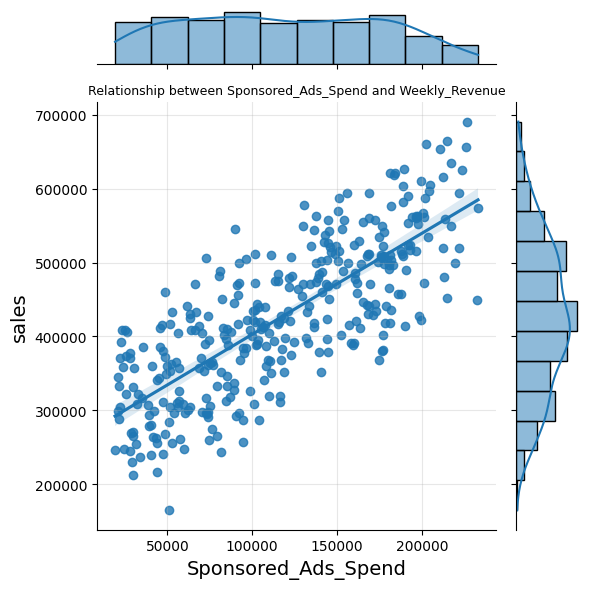

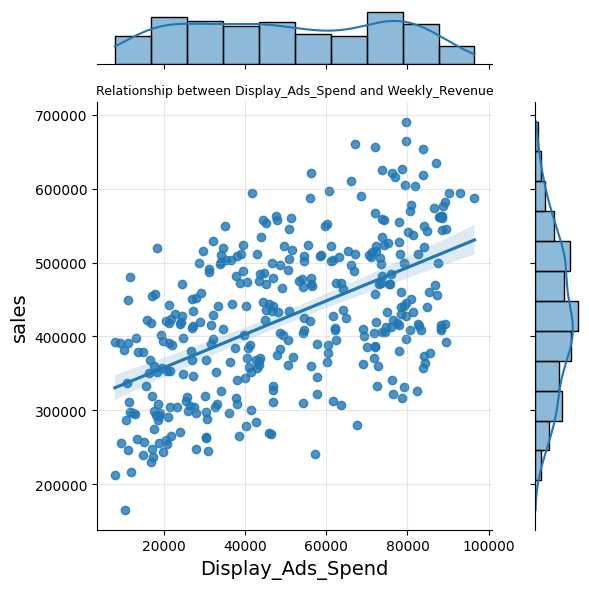

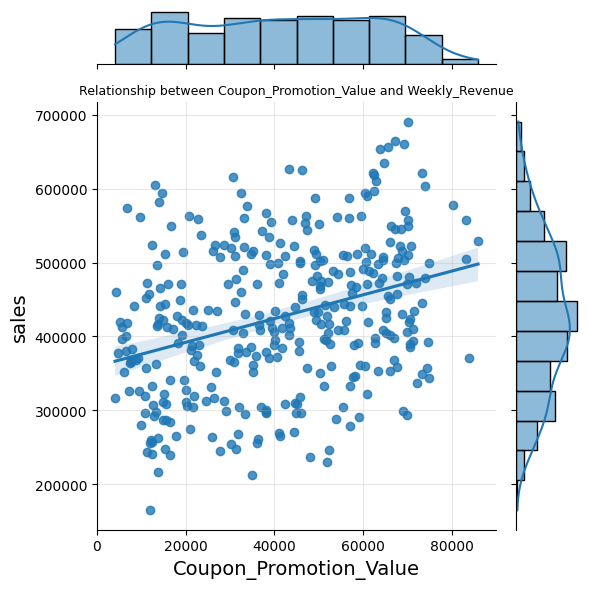

In [10]:
features = [ 'Sponsored_Ads_Spend','Display_Ads_Spend','Coupon_Promotion_Value' ]
for feature in features:
    sns.jointplot(x=feature, y='Weekly_Revenue', data=df , kind='reg')
    plt.title(f'Relationship between {feature} and Weekly_Revenue',fontsize=9)
    plt.xlabel(feature,fontsize=14)
    plt.ylabel('sales',fontsize=14)
    plt.grid(True,alpha=0.3)
    plt.tight_layout()
    plt.show()

In [11]:
# multicollinearity checking using correlation_matrix

correlation_matrix = df.corr(numeric_only="true")
print("Correlation matrix:")
correlation_matrix

Correlation matrix:


,Sponsored_Ads_Spend,Display_Ads_Spend,Coupon_Promotion_Value,Weekly_Revenue
Sponsored_Ads_Spend,1.000000,0.074689,0.037275,0.776286
Display_Ads_Spend,0.074689,1.000000,-0.013082,0.543101
Coupon_Promotion_Value,0.037275,-0.013082,1.000000,0.333412
Weekly_Revenue,0.776286,0.543101,0.333412,1.000000


<function matplotlib.pyplot.show(close=None, block=None)>

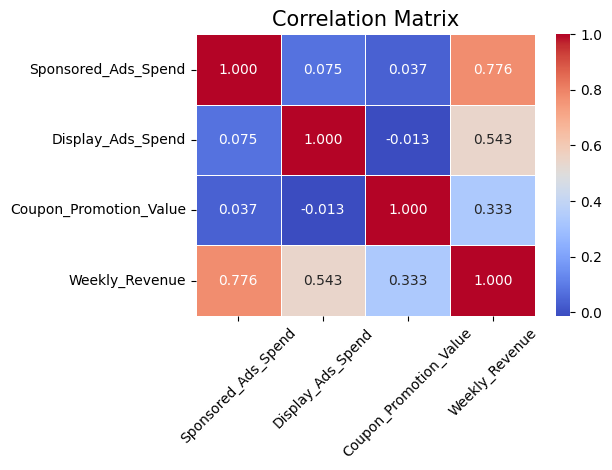

In [12]:
# plot the correlation matrixx
plt.Figure(figsize=(7,16))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm' ,fmt='.3f', linewidths=0.5)
plt.title('Correlation Matrix',fontsize=15)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show

In [13]:
features = ['Sponsored_Ads_Spend','Display_Ads_Spend','Coupon_Promotion_Value']
X=df[features] #independet variable 
y=df['Weekly_Revenue'] #dependent varable 

In [14]:
print("shape of X:", X.shape)
print("shape of y:", y.shape)

shape of X: (350, 3)
shape of y: (350,)


In [15]:
X.head()

,Sponsored_Ads_Spend,Display_Ads_Spend,Coupon_Promotion_Value
0,103743.86,78405.03,53513.13
1,168852.54,78253.85,15453.36
2,204276.58,60796.94,62416.07
3,131422.14,13233.02,62761.81
4,91936.12,87597.24,67411.60


In [16]:
y.head()

0    440432.71
1    511671.82
2    597009.58
3    397587.80
4    499559.25
Name: Weekly_Revenue, dtype: float64

In [17]:
df.shape

(350, 4)

In [18]:
# lets split the dataset into training and testing set

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Print the shape of the training and testing sets
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (280, 3)
Shape of X_test: (70, 3)
Shape of y_train: (280,)
Shape of y_test: (70,)


In [19]:
X_train.describe()

,Sponsored_Ads_Spend,Display_Ads_Spend,Coupon_Promotion_Value
count,280.000000,280.000000,280.000000
mean,116073.587000,50755.199143,41912.627107
std,56995.761362,24140.433282,20989.384843
min,19160.000000,8042.540000,4087.550000
25%,70508.182500,30169.447500,22911.222500
50%,111006.765000,48903.970000,43350.205000
75%,165329.252500,73558.855000,59647.972500
max,232297.760000,96474.490000,85917.600000


In [20]:
X_test.describe()

,Sponsored_Ads_Spend,Display_Ads_Spend,Coupon_Promotion_Value
count,70.000000,70.000000,70.000000
mean,121084.171143,48523.408429,38580.110143
std,58480.880044,24589.701265,20584.802035
min,20960.870000,10377.960000,5736.010000
25%,73859.667500,26755.960000,20408.015000
50%,116807.235000,45385.305000,38036.925000
75%,175907.832500,71745.405000,57484.387500
max,233083.540000,92877.800000,74916.900000


In [21]:
# imlementation of scaling 

from sklearn.preprocessing import StandardScaler , MinMaxScaler
sc = StandardScaler()
X_train[features]=sc.fit_transform(X_train[features])
X_test[features]=sc.transform(X_test[features])


In [22]:
X_train.describe()

,Sponsored_Ads_Spend,Display_Ads_Spend,Coupon_Promotion_Value
count,2.800000e+02,2.800000e+02,2.800000e+02
mean,6.344132e-18,6.026925e-17,2.696256e-17
std,1.001791e+00,1.001791e+00,1.001791e+00
min,-1.703409e+00,-1.772509e+00,-1.805332e+00
25%,-8.008839e-01,-8.542767e-01,-9.069073e-01
50%,-8.905740e-02,-7.682314e-02,6.861334e-02
75%,8.657461e-01,9.463163e-01,8.464803e-01
max,2.042823e+00,1.897280e+00,2.100289e+00


In [23]:
X_test.describe()

,Sponsored_Ads_Spend,Display_Ads_Spend,Coupon_Promotion_Value
count,70.000000,70.000000,70.000000
mean,0.088069,-0.092616,-0.159056
std,1.027894,1.020434,0.982480
min,-1.671756,-1.675593,-1.726653
25%,-0.741976,-0.995931,-1.026382
50%,0.012895,-0.222842,-0.184981
75%,1.051681,0.871061,0.743216
max,2.056635,1.748023,1.575242


In [24]:
# modelin - apply the multiple linear regression algorithm .

from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train,y_train)

# make the prediction on the train and test set
y_train_pred = lr.predict(X_train)
y_test_pred = lr.predict(X_test)

In [25]:
# comparing y_train_pred from y_train
print(y_train_pred[:5])
print(y_train[:5])

[418945.40203719 358039.82887537 407638.18391    423338.60805341
 424632.81981127]
228    422785.93
78     360376.95
90     415782.98
16     412611.92
66     425024.95
Name: Weekly_Revenue, dtype: float64


In [26]:
# evaluate the model using appropriate metrics 

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
r2_train = r2_score(y_train,y_train_pred)
r2_test = r2_score(y_test,y_test_pred)


mae_train = mean_absolute_error(y_train,y_train_pred)
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)


# adjusted R_squared
def adjusted_r2_score(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

n_train = X_train.shape[0]  # number of training samples
k = X_train.shape[1]  # number of features
adj_r2_train = adjusted_r2_score(r2_train, n_train, k)
n_test = X_test.shape[0]  # number of testing samples
adj_r2_test = adjusted_r2_score(r2_test, n_test, k)

# Print the evaluation metrics
print(f"R-squared (Train): {r2_train:.4f}")
print(f"R-squared (Test): {r2_test:.4f}")
print("." * 30)
print(f"Adjusted R-squared (Train): {adj_r2_train:.4f}")
print(f"Adjusted R-squared (Test): {adj_r2_test:.4f}")
print("." * 30)
print(f"Mean Absolute Error (Train): {mae_train:.4f}")
print(f"Mean Absolute Error (Test): {mae_test:.4f}")
print("." * 30)
print(f"Mean Squared Error (Train): {mse_train:.4f}")
print(f"Mean Squared Error (Test): {mse_test:.4f}")
print("." * 30)
print(f"Root Mean Squared Error (Train): {np.sqrt(mse_train):.4f}")
print(f"Root Mean Squared Error (Test): {np.sqrt(mse_test):.4f}")

R-squared (Train): 0.9341
R-squared (Test): 0.9457
..............................
Adjusted R-squared (Train): 0.9333
Adjusted R-squared (Test): 0.9432
..............................
Mean Absolute Error (Train): 19955.7997
Mean Absolute Error (Test): 19439.2145
..............................
Mean Squared Error (Train): 641988702.9791
Mean Squared Error (Test): 644913700.1191
..............................
Root Mean Squared Error (Train): 25337.4960
Root Mean Squared Error (Test): 25395.1511


In [27]:
print("Coefficients of the model:")
print(f"Intercept: {lr.intercept_:.4f}")
for feature, coef in zip(features, lr.coef_):
    print(f"{feature}: {coef:.4f}")

Coefficients of the model:
Intercept: 426469.9694
Sponsored_Ads_Spend: 73052.8996
Display_Ads_Spend: 50220.0865
Coupon_Promotion_Value: 32562.2343


In [28]:
# making another model without Coupon_Promotion_value 

features = ['Sponsored_Ads_Spend','Display_Ads_Spend']

X = df[features]
y = df['Weekly_Revenue']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=43)

from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train[features]=sc.fit_transform(X_train[features])
X_test[features]=sc.transform(X_test[features])

from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(X_train,y_train)


y_train_pred = lr.predict(X_train)
y_test_pred = lr.predict(X_test)

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)
mae_train = mean_absolute_error(y_train, y_train_pred)
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)

adj_r2_train = adjusted_r2_score(r2_train, n_train, k)
adj_r2_test = adjusted_r2_score(r2_test, n_test, k)

print(f"R-squared (Train): {r2_train:.4f}")
print(f"R-squared (Test): {r2_test:.4f}")
print("." * 30)
print(f"Adjusted R-squared (Train): {adj_r2_train:.4f}")
print(f"Adjusted R-squared (Test): {adj_r2_test:.4f}")
print("." * 30)
print(f"Mean Absolute Error (Train): {mae_train:.4f}")
print(f"Mean Absolute Error (Test): {mae_test:.4f}")
print("." * 30)
print(f"Mean Squared Error (Train): {mse_train:.4f}")
print(f"Mean Squared Error (Test): {mse_test:.4f}")
print("." * 30)
print(f"Root Mean Squared Error (Train): {np.sqrt(mse_train):.4f}")
print(f"Root Mean Squared Error (Test): {np.sqrt(mse_test):.4f}")

R-squared (Train): 0.8395
R-squared (Test): 0.8370
..............................
Adjusted R-squared (Train): 0.8378
Adjusted R-squared (Test): 0.8296
..............................
Mean Absolute Error (Train): 32812.9470
Mean Absolute Error (Test): 35282.5243
..............................
Mean Squared Error (Train): 1562771701.0754
Mean Squared Error (Test): 1924445591.2087
..............................
Root Mean Squared Error (Train): 39531.9074
Root Mean Squared Error (Test): 43868.5034


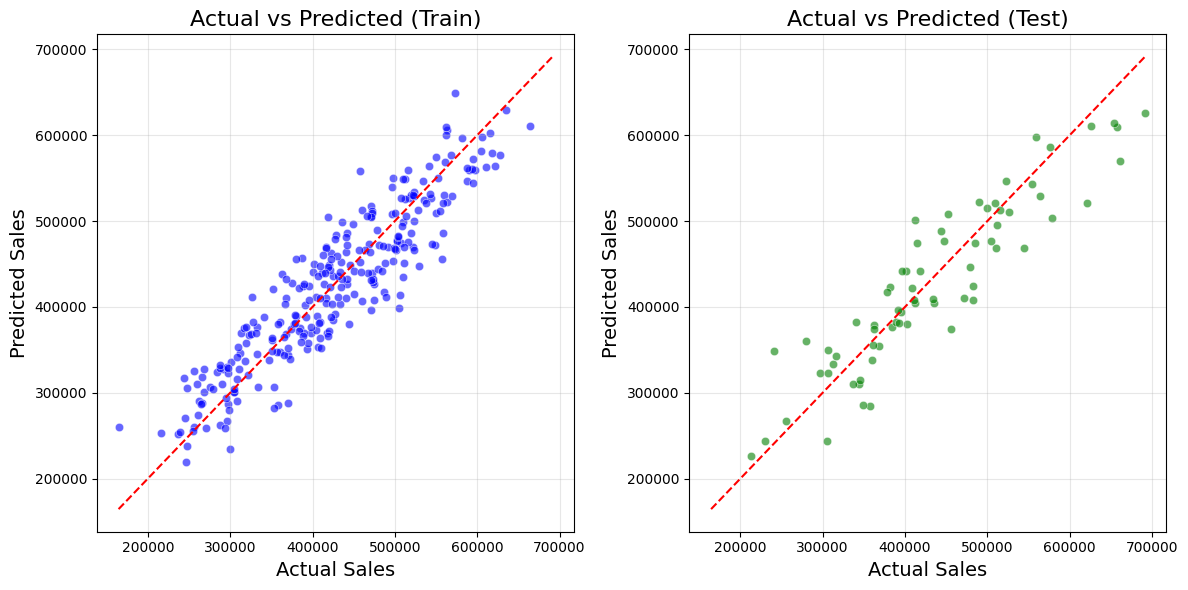

In [29]:
# Visualizing the predictions

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_train, y=y_train_pred, color='blue', alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')  # Line for perfect predictions
plt.title('Actual vs Predicted (Train)', fontsize=16)
plt.xlabel('Actual Sales', fontsize=14)
plt.ylabel('Predicted Sales', fontsize=14)
plt.grid(True, alpha=0.3)
plt.subplot(1, 2, 2)
sns.scatterplot(x=y_test, y=y_test_pred, color='green', alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')  # Line for perfect predictions
plt.title('Actual vs Predicted (Test)', fontsize=16)
plt.xlabel('Actual Sales', fontsize=14)
plt.ylabel('Predicted Sales', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [31]:
from statsmodels.stats.stattools import durbin_watson

residuals= y_test - y_test_pred
dw=durbin_watson(residuals)
print(f'durbin_watson statistic: {dw}')

durbin_watson statistic: 2.2206286325949804


In [32]:
# 12. Save the model
import joblib # joblib is used to save the model

# Save the linear regression model
joblib.dump(lr, 'linear_regression_model.pkl')

# Save the StandardScaler
joblib.dump(sc, 'standard_scaler.pkl')

print("Model and scaler saved successfully.")

Model and scaler saved successfully.
